In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# (2 балла) Задача 1. Пространство элементарных исходов для игр с кубиком и монеткой

Бросается кубик.

Если на нём выпала шестёрка, то кубик бросают ещё раз, иначе бросают монету.

Необходимо:

 - Описать пространство элементарных исходов
 - Создать (с помощью кода) таблицу, которая сопоставит исходы и их вероятности
 - Нарисовать функцию вероятности данной случайной величины
 - Посчитать ожидаемый выигрыш по правилам:

    - Герб стоит $100$ рублей
    - Решка отнимает $100$ рублей
    - Грань кубика даёт своё значение, умноженное на $10$

In [3]:

outcomes = (
    [(6, i) for i in range(1, 7)]
    + [(i, coin) for i in range(1, 6) for coin in ["Г", "Р"]]
)

print(outcomes)
print("Количество исходов:", len(outcomes))


[(6, 1), (6, 2), (6, 3), (6, 4), (6, 5), (6, 6), (1, 'Г'), (1, 'Р'), (2, 'Г'), (2, 'Р'), (3, 'Г'), (3, 'Р'), (4, 'Г'), (4, 'Р'), (5, 'Г'), (5, 'Р')]
Количество исходов: 16


In [4]:
probs = [ 1/36 if first == 6 else 1/12 for first, second in outcomes]

probably_table = pd.DataFrame({
    'Исход': outcomes,
    'Вероятность': probs
})

probably_table


,Исход,Вероятность
0,"(6, 1)",0.027778
1,"(6, 2)",0.027778
2,"(6, 3)",0.027778
3,"(6, 4)",0.027778
4,"(6, 5)",0.027778
5,"(6, 6)",0.027778
6,"(1, Г)",0.083333
7,"(1, Р)",0.083333
8,"(2, Г)",0.083333
9,"(2, Р)",0.083333


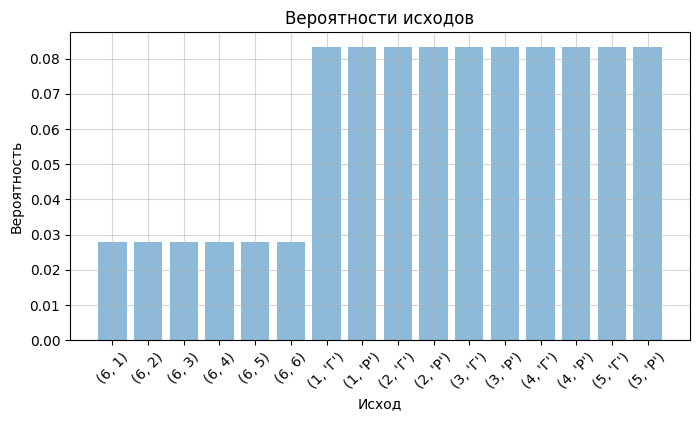

In [5]:
plt.figure(figsize=(8, 4))

plt.bar(
    probably_table["Исход"].astype(str),
    probably_table["Вероятность"],
    alpha=.5
)

plt.xlabel("Исход")
plt.ylabel("Вероятность")
plt.title("Вероятности исходов")
plt.grid(alpha=.5)
plt.xticks(rotation=45)
plt.show()

In [6]:
wins = []

for first, second in outcomes:
    win = first * 10

    if second == "Г":
        win += 100
    elif second == "Р":
        win -= 100
    else:
        win += second * 10

    wins.append(win)

probably_table["Выигрыш"] = wins
probably_table["Вероятность * Выигрыш"] = (
    probably_table["Вероятность"] * probably_table["Выигрыш"]
)

expected_win = probably_table["Вероятность * Выигрыш"].sum()

print(probably_table.head())
print("Ожидаемый выигрыш:", round(expected_win, 2), "руб.")

    Исход  Вероятность  Выигрыш  Вероятность * Выигрыш
0  (6, 1)     0.027778       70               1.944444
1  (6, 2)     0.027778       80               2.222222
2  (6, 3)     0.027778       90               2.500000
3  (6, 4)     0.027778      100               2.777778
4  (6, 5)     0.027778      110               3.055556
Ожидаемый выигрыш: 40.83 руб.


# (3 балла) Задача 2. Окупаемость и биномиальное распределение

На онлайн-площадку заходят пользователи, каждый из которых купит продукт с вероятностью $10\%$.

Цена продукта — $1200$ рублей.

Чтобы площадка окупалась, необходимо заработать минимум $500.000$ рублей.

Сколько пользователей ($N$) нужно пригласить, чтобы заработать $500.000$ рублей с вероятностью как минимум $95\%$?

-----
**Подсказка**

На вопрос можно ответить с помощью:

  1\) цикла `for`, запущенного по сетке различных N;

  2\) цикла `while` с условием достижения вероятности порога в 95%.



In [13]:
p = 0.1
price = 1200
bound = 500000
alpha = 0.95

In [14]:
min_purchases = int(bound / price + 0.5)

In [15]:
### Твоё решение здесь
from scipy.stats import binom

N = min_purchases

while binom.sf(min_purchases - 1, n=N, p=p) < alpha:
    N += 1

print("Минимальное число пользователей:", N)
print(
    "Вероятность окупаемости:",
    binom.sf(min_purchases - 1, n=N, p=p)
)
    

Минимальное число пользователей: 4494
Вероятность окупаемости: 0.9502719796089382


# (3 балла) Задача 3. Время на принятие решения горячими и холодными пользователями

Аналитики нашего магазина разделили пользователей на две категории — «горячие» и «холодные».

«Горячим» пользователям требуется в среднем 8 минут на принятие решения о покупке, а «холодным» требуется в среднем $17$ минут на принятие решения. Время, необходимое для принятия решения, у обоих распределено *экспоненциально*.

В течение последней минуты к нам зашло $4$ пользователя: два «горячих» и два «холодных».

Какова вероятность, что за $15$ минут мы не получим от них ни одной покупки?



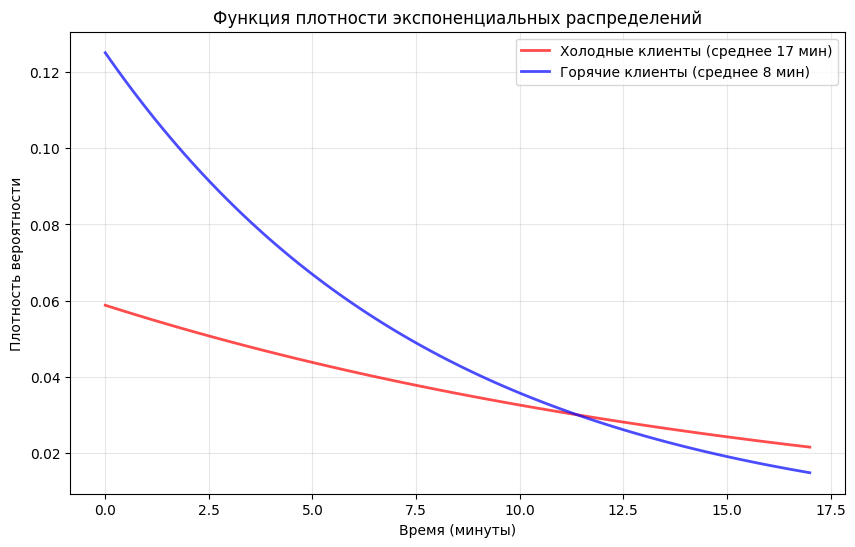

In [21]:
### Твоё решение здесь
from scipy.stats import expon

hot_client_min = 8
cold_client_min = 17

# 1 min, 2 hot, 2 cold
time = np.linspace(0,17,100)
pdf_hot = expon.pdf(time, scale=hot_client_min)
pdf_cold = expon.pdf(time, scale=cold_client_min)

plt.figure(figsize=(10, 6))
plt.plot(time, pdf_cold, color='red',   alpha=.7, linewidth=2, label='Холодные клиенты (среднее 17 мин)')
plt.plot(time, pdf_hot,  color='blue',  alpha=.7, linewidth=2, label='Горячие клиенты (среднее 8 мин)')

plt.title("Функция плотности экспоненциальных распределений")
plt.xlabel("Время (минуты)")
plt.ylabel("Плотность вероятности")
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.show()

In [26]:
p_hot_wait = expon.sf(15, scale=hot_client_min)
p_cold_wait = expon.sf(15, scale=cold_client_min)

p_no_sales = p_hot_wait**2 * p_cold_wait**2

print(
    "Вероятность ни одной покупки:",
    round(p_no_sales * 100, 4),
    "%"
)

Вероятность ни одной покупки: 0.4027 %


# (2 балла) Задача 4. Кубическая плотность

Пусть

$$
\rho(x)=
\begin{cases}
cx^3, & x\in[-2,0],\\
0, & x\notin[-2,0].
\end{cases}
$$

Найти $c$, вероятность $\mathbb{P}(-1.5\leq\xi<-0.5)$ и функцию распределения $F_\xi(x)$.

**Решение**

1. 
$$
1=\int_{-\infty}^{+\infty}\rho(x)\,dx
=c\int_{-2}^{0}x^3\,dx
=c\left.\frac{x^4}{4}\right|_{-2}^{0}
=-4c.
$$

Следовательно,

$$
c=-\frac14.
$$

Самопроверка: $\rho(x)=-\frac14x^3\geq 0$ на $[-2,0]$. 

2. 
$$
\begin{aligned}
\mathbb{P}(-1.5\leq\xi<-0.5)
&=\int_{-3/2}^{-1/2}-\frac14x^3\,dx
&=\left.-\frac{x^4}{16}\right|_{-3/2}^{-1/2}
=\frac{5}{16}.
\end{aligned}
$$

3. 
$$
F_\xi(x)=\int_{-\infty}^{x}\rho(t)\,dt.
$$

$$
F_\xi(x)=\int_{-2}^{x}-\frac14t^3\,dt
=\left.-\frac{t^4}{16}\right|_{-2}^{x}
=1-\frac{x^4}{16}.
$$

Таким образом,

$$
F_\xi(x)=
\begin{cases}
0, & x<-2,\\
1-\dfrac{x^4}{16}, & -2\leq x\leq 0,\\
1, & x>0.
\end{cases}
$$
